# Lecture 22 — Time series and spectral methods

We sample the sum of two cosines for two seconds. One completes one cycle per second and the other completes three. Can we separate them using only the 32 sampled values? We will predict where the peaks belong, find them with a Fourier transform, and reconstruct the slower wave.

Run the cells in order with NumPy and Matplotlib. All six sections use signals generated here. The closing exercise reads a CSV file.

[Lecture notes](https://teaching.borisbolliet.io/c1-2026/materials/class22/notes.pdf) · [Convolution and FFT animation](https://teaching.borisbolliet.io/c1-2026/animations/class22-fourier/)

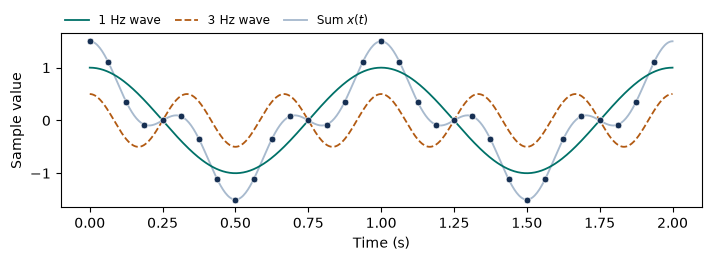

In [1]:
%matplotlib inline
import math
import time

import matplotlib.pyplot as plt
import numpy as np

def two_waves(t):
    """Values of the two component cosines at times t, in seconds."""
    return np.cos(2 * np.pi * t), 0.5 * np.cos(2 * np.pi * 3 * t)


def plot_waveform(ax, t, samples):
    """Plot both cosines and their continuous sum, with dots at the sampled values."""
    times = np.linspace(t[0], t[-1] + (t[1] - t[0]), 16 * len(t) + 1)
    slow_wave, fast_wave = two_waves(times)
    ax.plot(times, slow_wave, color="#007168", lw=1.3, label="1 Hz wave")
    ax.plot(times, fast_wave, "--", color="#b25a12", lw=1.3, label="3 Hz wave")
    ax.plot(times, slow_wave + fast_wave, color="#a8bace", lw=1.35,
            label="Sum $x(t)$", zorder=1)
    ax.plot(t, samples, "o", color="#162f52", ms=4.8, markeredgecolor="white",
            markeredgewidth=0.45, zorder=3)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
              frameon=False, fontsize=8.5, borderaxespad=0, columnspacing=1.2)


sample_rate = 16                         # samples per second
t_signal = np.arange(32) / sample_rate
slow, fast = two_waves(t_signal)
signal = slow + fast

fig, ax = plt.subplots(figsize=(7, 2.5), layout="constrained")
plot_waveform(ax, t_signal, signal)
ax.set(xlabel="Time (s)", ylabel="Sample value")
plt.show()

## 1. Sampled time series

### 1.1. Sampling interval and the Nyquist frequency

At 16 samples per second, consecutive readings are 62.5 ms apart. The **Nyquist frequency** is half the sampling rate, or 8 Hz here. In the middle row, start at the first peak and count the intervals to the next peak. Now compare the dots in the first and last rows. Could we tell which of those two waves produced the readings?

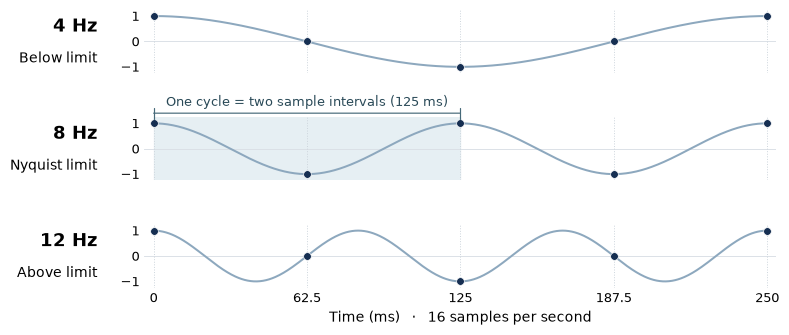

In [2]:
def plot_nyquist(sample_rate=16):
    """Compare three cosines sampled at the same five instants."""
    samples = np.arange(5) / sample_rate
    time = np.linspace(samples[0], samples[-1], 601)
    sample_ms = 1000 * samples
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8.0, 3.35))
    fig.subplots_adjust(left=0.19, right=0.98, top=0.98, bottom=0.15, hspace=0.69)
    frequencies = [sample_rate / 4, sample_rate / 2, 3 * sample_rate / 4]
    for ax, f, label in zip(axes, frequencies, ["Below limit", "Nyquist limit", "Above limit"]):
        ax.plot(1000*time, np.cos(2*np.pi*f*time), color="#8da8be", lw=1.45)
        ax.plot(sample_ms, np.cos(2*np.pi*f*samples), "o", color="#162f52",
                ms=5.5, mec="white", mew=0.45, zorder=3)
        ax.set(ylim=(-1.25, 1.25), yticks=[-1, 0, 1], xticks=sample_ms)
        ax.margins(x=0.015)
        ax.spines[:].set_visible(False)
        ax.axhline(0, color="#d9dfe5", lw=0.65, zorder=0)
        ax.grid(axis="x", color="#cdd5dc", lw=0.7, ls=":")
        ax.tick_params(length=0, labelsize=9)
        ax.text(-0.075, 0.73, f"{f:g} Hz", transform=ax.transAxes,
                ha="right", va="center", fontsize=13, weight="bold")
        ax.text(-0.075, 0.23, label, transform=ax.transAxes,
                ha="right", va="center", fontsize=10)

    middle = axes[1]
    period_ms = sample_ms[2]
    middle.axvspan(0, period_ms, color="#e6eff3", zorder=-2)
    middle.annotate("", xy=(0, 1.4), xytext=(period_ms, 1.4), annotation_clip=False,
                    arrowprops=dict(arrowstyle="|-|", lw=0.85, color="#466979",
                                    shrinkA=0, shrinkB=0, mutation_scale=4))
    middle.text(period_ms/2, 1.56, f"One cycle = two sample intervals ({period_ms:g} ms)",
                ha="center", va="bottom", color="#294957", fontsize=9.5)
    axes[-1].set_xticks(sample_ms, labels=[f"{v:g}" for v in sample_ms])
    axes[-1].set_xlabel(f"Time (ms)   ·   {sample_rate:g} samples per second")
    return fig


plot_nyquist(sample_rate)
plt.show()

The 8 Hz wave completes a cycle in two sampling intervals. The 4 Hz and 12 Hz waves both give readings $1,0,-1,0,1$. At this sampling rate a 12 Hz cosine can therefore appear as a 4 Hz cosine. These frequencies are aliases on this grid.

## 2. Fourier coefficients and reconstruction

### 2.1. Definition and frequencies

Take eight readings of the 4 Hz cosine from §1.1 at 16 samples per second. Eight sampling intervals span $8/16=0.5$ seconds. In that time the cosine completes two cycles. The **discrete Fourier transform** (DFT) compares the readings $x_n$ with waves of different frequencies. Coefficient $X_k$ belongs to the wave with $k$ cycles in those $N$ intervals.

$$X_k=\sum_{n=0}^{N-1}x_n\,e^{-2\pi i kn/N},\qquad k=0,1,\ldots,N-1.$$

For our predicted index $k=2$, the four nonzero readings are $1,-1,1,-1$. The weights at those four sample times are also $1,-1,1,-1$. Each product is 1, so we expect $X_2=4$.

In [3]:
n = np.arange(8)
t = n / 16  # seconds
x = np.cos(2 * np.pi * 4 * t)
weights = np.exp(-2j * np.pi * 2 * n / len(x))
products = x * weights
print('Real parts of the eight products:', np.rint(products.real).astype(int))
np.testing.assert_allclose(products.imag, 0, atol=1e-12)
X = np.fft.fft(x)
print('Sum of the products:', round(products.sum().real, 2))
print('Index     Frequency (Hz)     Magnitude')
for k, (f, magnitude) in enumerate(zip(np.fft.fftfreq(len(x), d=1/16), np.abs(X))):
    print(f'{k:5d} {f:25.3f} {magnitude:13.2f}')
np.testing.assert_allclose(products.sum(), X[2])

Real parts of the eight products: [1 0 1 0 1 0 1 0]
Sum of the products: 4.0
Index     Frequency (Hz)     Magnitude
    0                     0.000          0.00
    1                     2.000          0.00
    2                     4.000          4.00
    3                     6.000          0.00
    4                    -8.000          0.00
    5                    -6.000          0.00
    6                    -4.000          4.00
    7                    -2.000          0.00


Rows 2 and 6 have magnitude 4 at frequencies $+4$ Hz and $-4$ Hz. Both belong to the same 4 Hz cosine. A real cosine is the sum of two complex waves rotating in opposite directions; the two rows give their coefficients.

### 2.2. Finding the two frequencies

Return to the signal in the opening cell. The two-second record gives a bin spacing of $1/2=0.5$ Hz. Which bin numbers correspond to 1 and 3 Hz? A cosine of amplitude $a$ on an interior bin gives a coefficient of magnitude $32a/2$ there. Predict the two heights before running the cell. For real readings, `np.fft.rfft` returns the coefficients for zero and positive frequencies.

Bin 2: 1 Hz, magnitude 16.0
Bin 6: 3 Hz, magnitude 8.0


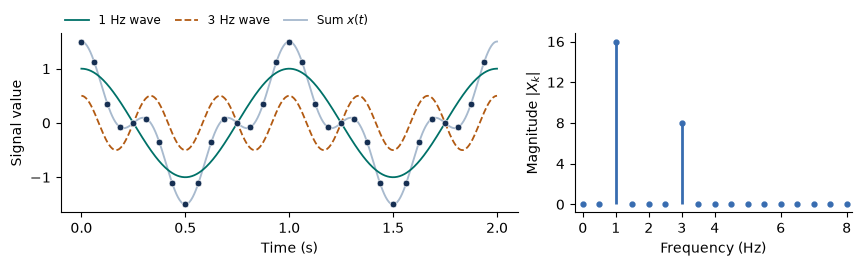

In [4]:
def plot_tones(t, x, f, spectrum, filtered=None, cutoff=2.0):
    """Show the sampled waveform and its one-sided Fourier magnitudes."""
    fig, (time_ax, freq_ax) = plt.subplots(1, 2, figsize=(8.5, 2.55),
                                          layout="constrained", width_ratios=[1.65, 1])
    if filtered is None:
        plot_waveform(time_ax, t, x)
    else:
        time_ax.plot(t, x, "o-", color="#386cb0", ms=3, lw=1.2, label="measured signal")
        time_ax.plot(t, filtered, "s--", ms=2.5, lw=1.3, color="#b27813",
                     label=f"after {cutoff:g} Hz cut-off")
        time_ax.legend(fontsize=8)
    time_ax.set(xlabel="Time (s)", ylabel="Signal value", xticks=[0, 0.5, 1, 1.5, 2])
    freq_ax.vlines(f, 0, np.abs(spectrum), lw=2, color="#386cb0")
    freq_ax.plot(f, np.abs(spectrum), "o", ms=3.5, color="#386cb0")
    if filtered is not None:
        freq_ax.axvspan(cutoff, 8.15, color="#e6e7eb", zorder=-2)
        if cutoff < 6:
            freq_ax.text((cutoff + 8) / 2, 13, "removed", ha="center", fontsize=10)
    freq_ax.set(xlabel="Frequency (Hz)", ylabel=r"Magnitude $|X_k|$",
                xlim=(-0.25, 8.15), xticks=[0, 1, 2, 3, 4, 6, 8], yticks=[0, 4, 8, 12, 16])
    for ax in (time_ax, freq_ax):
        ax.spines[["right", "top"]].set_visible(False)
    return fig


frequencies = np.fft.rfftfreq(signal.size, d=1 / sample_rate)
coefficients = np.fft.rfft(signal)
peaks = np.flatnonzero(np.abs(coefficients) > 1e-10)
for k in peaks:
    print(f'Bin {k}: {frequencies[k]:g} Hz, magnitude {abs(coefficients[k]):.1f}')
np.testing.assert_allclose(np.abs(coefficients[peaks]), [16, 8])
plot_tones(t_signal, signal, frequencies, coefficients)
plt.show()

### 2.3. Removing one wave

Suppose we retain every coefficient up to 2 Hz and set the others to zero. Which cosine should the inverse transform recover? We pass the retained coefficients and the original sample count to `np.fft.irfft`. After running the cell, change the cut-off to 4 Hz and compare the two curves again.

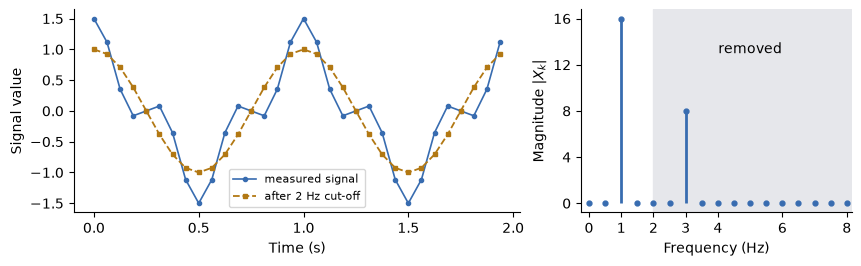

Largest difference from the predicted wave: 8.88e-16


In [5]:
cutoff = 2.0                             # Hz
retained = np.where(frequencies <= cutoff, coefficients, 0)
reconstructed = np.fft.irfft(retained, n=signal.size)
plot_tones(t_signal, signal, frequencies, coefficients, reconstructed, cutoff)
plt.show()
expected = (1 <= cutoff) * slow + (3 <= cutoff) * fast
print(f"Largest difference from the predicted wave: {np.max(np.abs(reconstructed - expected)):.2e}")
np.testing.assert_allclose(reconstructed, expected, atol=1e-12)

At 2 Hz only the slow cosine survives. The inverse transform uses the complex coefficients, including their phases. To compare the *strength* of different frequencies we can instead plot $P_k=|X_k|^2$, giving a **periodogram**. For our two cosines the peak powers are 256 and 64. The following functions use this convention. By default they remove the mean and apply a window. We examine the effect of the window in §4.

In [6]:
def fourier(x, dt=1.0, n=None, window=True, axis=-1):
    """Frequencies and Fourier coefficients of real samples taken every dt.

    The mean of each series is removed first. With window=True the samples
    are multiplied by a Hann window, which reduces leakage between
    frequencies. An n larger than the number of samples m pads them with
    zeros: the frequencies are then k / (n dt), a finer grid.

    Returns
    -------
    f : numpy.ndarray, shape (n // 2 + 1,)
        Frequencies in cycles per unit of t, from 0 to the Nyquist frequency.
    X : numpy.ndarray of complex
        The coefficients of numpy.fft.rfft, with n // 2 + 1 values along axis.
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    m = x.shape[-1]
    n = m if n is None else n
    x = x - x.mean(axis=-1, keepdims=True)
    if window:
        x = x * np.hanning(m)  # shape (m,), broadcast over the leading axes
    X = np.fft.rfft(x, n=n)
    return np.fft.rfftfreq(n, d=dt), np.moveaxis(X, -1, axis)


def periodogram(x, dt=1.0, n=None, window=True, axis=-1):
    """Frequencies and power |X_k|**2 of real samples; arguments as for `fourier`.

    Examples
    --------
    >>> x = np.cos(2 * np.pi * np.arange(16) / 4)     # period of 4 samples
    >>> f, power = periodogram(x, window=False)
    >>> float(f[np.argmax(power)])
    0.25
    """
    f, X = fourier(x, dt, n, window, axis)
    return f, np.abs(X) ** 2


def dominant_period(f, power, shortest, longest, axis=-1):
    """Period 1 / f of the largest power among periods from shortest to longest.

    Examples
    --------
    >>> f = np.array([0.0, 0.1, 0.2, 0.3])
    >>> float(dominant_period(f, np.array([9.0, 1.0, 3.0, 2.0]), 3, 20))
    5.0
    """
    power = np.moveaxis(power, axis, -1)
    band = (f >= 1 / longest) & (f <= 1 / shortest)
    return 1 / f[np.argmax(np.where(band, power, -np.inf), axis=-1)]

In [7]:
f, power = periodogram(signal, dt=1/sample_rate, window=False)
print("Power at 1 and 3 Hz:", power[peaks].round(2))

Power at 1 and 3 Hz: [256.  64.]


### 2.4. Real series and the real-input transform

For real samples, $X_{N-k}=\overline{X_k}$: **conjugate symmetry**. $X_0$ is real, and for even $N$ so is $X_{N/2}$. `np.fft.rfft` returns $X_0,\ldots,X_{N//2}$, `N // 2 + 1` values. A `float64` takes 8 bytes and a `complex128`, two `float64`, 16 bytes.

In [8]:
x = np.array([2.0, 0.0, 3.0, 0.0, 0.0, 1.0])
X = np.fft.fft(x)
print(X.round(3))
print('X[N-k] == conj(X[k]):', np.allclose(X[1:][::-1], X[1:].conj()))
print('rfft:', np.fft.rfft(x).round(3))

x = np.zeros(374)                                  # 374 real-valued readings
print('bytes: series', x.nbytes, ' fft', np.fft.fft(x).nbytes, ' rfft', np.fft.rfft(x).nbytes)

[6.+0.j    1.-1.732j 0.+3.464j 4.+0.j    0.-3.464j 1.+1.732j]
X[N-k] == conj(X[k]): True
rfft: [6.+0.j    1.-1.732j 0.+3.464j 4.+0.j   ]
bytes: series 2992  fft 5984  rfft 3008


### 2.5. Inverse transforms and their lengths

Seven coefficients could have come from 12 or 13 real readings: both lengths give `N // 2 + 1 == 7`. Here we start with 13 readings. To reconstruct all of them with `irfft`, we pass the original length. The default assumes 12. The related function `hfft` takes an input with conjugate symmetry and gives a real spectrum. It uses the same default length.

In [9]:
x = np.arange(13.0)
R = np.fft.rfft(x)
print('rfft values:', R.size)
print('irfft lengths:', np.fft.irfft(R).size, np.fft.irfft(R, n=13).size)
print('hfft lengths:', np.fft.hfft(R).size, np.fft.hfft(R, n=13).size)
print('irfft without n starts with', np.fft.irfft(R)[:2].round(3))
print('hfft(a, n) == n * irfft(conj(a), n):', np.allclose(np.fft.hfft(R, n=13), 13 * np.fft.irfft(R.conj(), n=13)))

rfft values: 7
irfft lengths: 12 13
hfft lengths: 12 13
irfft without n starts with [0.542 0.981]
hfft(a, n) == n * irfft(conj(a), n): True


## 3. Fast Fourier transform

### 3.1. The DFT as a matrix–vector product

The weights we used for $X_2$ form one row of a matrix $W$. Row $k$ contains the weights $W_{kn}=e^{-2\pi ikn/N}$ for coefficient $X_k$. Multiplying all rows by the same readings gives $\boldsymbol X=W\boldsymbol x$. There are $N$ products per row and $N$ rows. Compare the matrix product with NumPy's FFT, which computes the same coefficients without storing this matrix.

In [10]:
N = 8
k = np.arange(N)
W = np.exp(-2j * np.pi * np.outer(k, k) / N)
x = np.random.default_rng(0).standard_normal(N)
print('W @ x == fft(x):', np.allclose(W @ x, np.fft.fft(x)), ' W bytes:', W.nbytes)
print('MiB of W for N = 4096:', 4096 ** 2 * 16 / 2 ** 20)

W @ x == fft(x): True  W bytes: 1024
MiB of W for N = 4096: 256.0


### 3.2. Splitting into even and odd samples

For four samples `[3, 6, 9, 12]`, the even positions contain 3 and 9. Their two-point DFT is their sum and difference, `[12, -6]`. The odd positions similarly give `[18, -6]`. We can already form two coefficients: $X_0=12+18=30$ and $X_2=12-18=-6$.

For $k=1$, the odd difference is multiplied by $e^{-2\pi i/4}=-i$. Its contribution is $6i$. Add and subtract it from the even difference to obtain $X_1$ and $X_3$. [Step through the four calculations](https://teaching.borisbolliet.io/c1-2026/animations/class22-fourier/?view=fft).

In [11]:
x = np.array([3., 6., 9., 12.])
E, O = np.fft.fft(x[::2]), np.fft.fft(x[1::2])
X = np.array([E[0]+O[0], E[1]-1j*O[1], E[0]-O[0], E[1]+1j*O[1]])
print('E =', E, ' O =', O)
print('X =', X)
np.testing.assert_allclose(X, np.fft.fft(x))

E = [12.+0.j -6.+0.j]  O = [18.+0.j -6.+0.j]
X = [30.+0.j -6.+6.j -6.+0.j -6.-6.j]


For a longer power-of-two input, repeat the same split on each half until only one sample remains. Each level processes $N$ values, and there are $\log_2 N$ levels.

In [12]:
def fft_recursive(x):
    """DFT of x, len(x) a power of two, by splitting into even and odd samples."""
    N = len(x)
    if N == 1:
        return np.asarray(x, dtype=complex)
    E, O = fft_recursive(x[0::2]), fft_recursive(x[1::2])
    w = np.exp(-2j * np.pi * np.arange(N // 2) / N)
    return np.concatenate([E + w * O, E - w * O])


x = np.random.default_rng(1).standard_normal(16)
print('recursive == np.fft.fft:', np.allclose(fft_recursive(x), np.fft.fft(x)))

recursive == np.fft.fft: True


### 3.3. Measured cost and padded sizes

Median times of a matrix–vector product with a precomputed $W$ and of `np.fft.fft`, then FFT lengths with and without a large prime factor. A common remedy for an awkward length is to pad with zeros to $N=2^{\lceil\log_2 n\rceil}$.

In [13]:
def seconds(function, *args, repeat=5):
    """Median elapsed time of function(*args), after one untimed call."""
    function(*args)
    durations = []
    for _ in range(repeat):
        start = time.perf_counter()
        function(*args)
        durations.append(time.perf_counter() - start)
    return float(np.median(durations))


rng = np.random.default_rng(0)
print('     N   matrix (ms)   fft (ms)   ratio   N/log2 N')
for N in (256, 512, 1024):
    k = np.arange(N)
    W = np.exp(-2j * np.pi * np.outer(k, k) / N)
    x = rng.standard_normal(N)
    t_matrix, t_fft = seconds(W.__matmul__, x), seconds(np.fft.fft, x)
    print(f'{N:6d} {1e3 * t_matrix:12.3f} {1e3 * t_fft:10.4f} {t_matrix / t_fft:7.0f} {N / math.log2(N):9.0f}')
del W
for N, factors in ((2**20, '2**20'), (2**20 - 3, 'prime')):
    x = rng.standard_normal(N)
    print(f'{N:9d} {factors:6s} fft: {1e3 * seconds(np.fft.fft, x):6.2f} ms')
print('374 samples padded to', 2 ** math.ceil(math.log2(374)))

     N   matrix (ms)   fft (ms)   ratio   N/log2 N
   256        0.008     0.0033       2        32
   512        0.025     0.0038       7        57
  1024        0.174     0.0067      26       102


  1048576 2**20  fft:  10.91 ms


  1048573 prime  fft:  79.83 ms
374 samples padded to 512


### 3.4. Choosing the time axis

Store the slow wave in the first column and the fast wave in the second. Each column now contains 32 samples. To transform each wave separately we take the FFT along the rows ($\mathtt{axis}=0$). Each output column contains 17 coefficients, from 0 to 8 Hz.

In [14]:
channels = np.column_stack([slow, fast])
channel_fft = np.fft.rfft(channels, axis=0)
print("Input and output shapes:", channels.shape, channel_fft.shape)
print("Peak frequency in each channel (Hz):", frequencies[np.abs(channel_fft).argmax(axis=0)])

Input and output shapes: (32, 2) (17, 2)
Peak frequency in each channel (Hz): [1. 3.]


## 4. Estimating a period between frequency bins

### 4.1. Zero padding and the frequency grid

Consider a cosine with a known period of eight days. We record 141 daily values. Its 17.625 cycles fall between two Fourier bins. How close will the largest bin come to the true period? Padding $N$ samples with zeros to $n$ evaluates the same sum at the finer grid $k/(n\Delta t)$. Here $T=N\Delta t$ is the duration associated with the original frequency grid. Padding samples the peak more finely. Resolving two nearby frequencies generally requires a longer observation.

### 4.2. Leakage

**Spectral leakage** is the appearance of power at frequencies other than those of the oscillations in the signal. The DFT treats the record as one period of a periodic series, which jumps where $x_{N-1}$ meets $x_0$ when the record holds a non-integer number of cycles.

### 4.3. The Hann window

The **Hann window** $w_n=\sin^2(\pi n/(N-1))$ brings both ends of the record to zero.

Hann window of 5: [0.  0.5 1.  0.5 0. ]
grid: 7.833333333333334  padded: 8.0
power at 0.25 per day: 4.0e-04 without window, 3.7e-09 with Hann


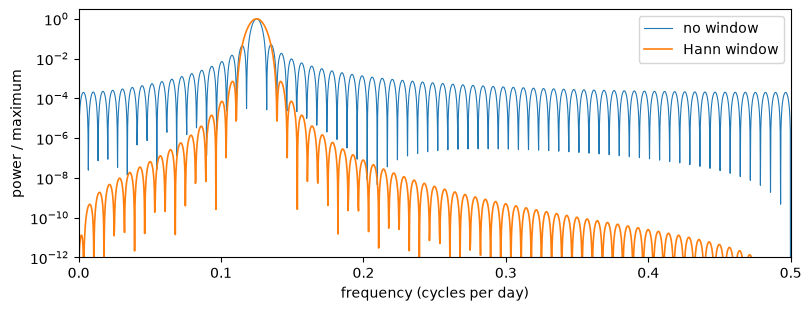

In [15]:
print('Hann window of 5:', np.hanning(5))
x = np.cos(2 * np.pi * np.arange(141) / 8.0)      # 17.625 cycles in the record
print('grid:', dominant_period(*periodogram(x, window=False), 3, 20),
      ' padded:', dominant_period(*periodogram(x, n=4096, window=False), 3, 20))
f, p = periodogram(x, n=4096, window=False)
f, q = periodogram(x, n=4096)
k = np.searchsorted(f, 0.25)
print(f'power at 0.25 per day: {p[k] / p.max():.1e} without window, {q[k] / q.max():.1e} with Hann')

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.semilogy(f, p / p.max(), lw=0.8, label='no window')
ax.semilogy(f, q / q.max(), lw=1.2, label='Hann window')
ax.set(xlabel='frequency (cycles per day)', ylabel='power / maximum', ylim=(1e-12, 3), xlim=(0, 0.5))
ax.legend()
plt.show()

## 5. Convolution and moving averages

### 5.1. Convolution and the convolution theorem

Use the same four samples as in the FFT example, with zeros beyond each end. Give the current sample and its two predecessors weight $1/3$ each. At $m=2$ the output is $(9+6+3)/3=6$. Move one sample to the right: which value leaves the window and which enters?

[Move the kernel in the animation](https://teaching.borisbolliet.io/c1-2026/animations/class22-fourier/) or change the three output positions in the plot below.

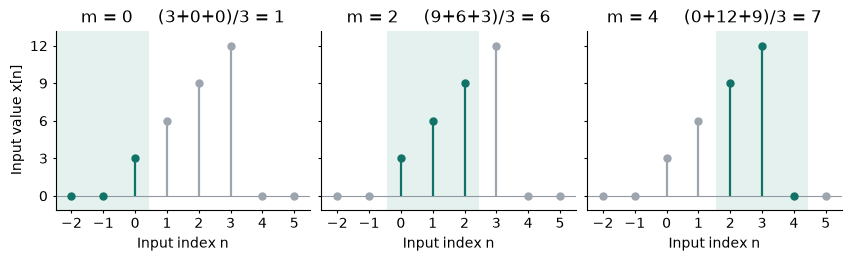

In [16]:
def plot_window(x, width, positions):
    """Draw the input samples used for each output of a linear convolution."""
    fig, axes = plt.subplots(1, len(positions), figsize=(8.4, 2.5),
                             layout="constrained", sharey=True, squeeze=False)
    indices = np.arange(1-width, len(x) + width-1)
    values = np.zeros(indices.shape)
    values[(indices >= 0) & (indices < len(x))] = x
    for ax, m in zip(axes[0], positions):
        active = (indices > m-width) & (indices <= m)
        ax.axvspan(m-width+0.55, m+0.45, color="#e5f1ee", lw=0)
        ax.axhline(0, color="#9399a2", lw=0.8)
        for selected, color in [(False, "#9da5af"), (True, "#117368")]:
            use = active == selected
            ax.vlines(indices[use], 0, values[use], color=color, lw=1.6)
            ax.scatter(indices[use], values[use], color=color, s=25, zorder=3)
        terms = "+".join(f"{v:g}" for v in values[active][::-1])
        ax.set(title=f"m = {m}     ({terms})/{width} = {values[active].mean():g}",
               xlabel="Input index n", xticks=indices, yticks=[0, 3, 6, 9, 12],
               xlim=(indices[0]-0.5, indices[-1]+0.5), ylim=(-1.1, 13.2))
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(length=2)
    axes[0, 0].set_ylabel("Input value x[n]")
    return fig


x = np.array([3., 6., 9., 12.])
plot_window(x, width=3, positions=[0, 2, 4])
plt.show()

For a kernel $k$ of length $w$, the output at $m$ is $y_m=\sum_{j=0}^{w-1}k_j x_{m-j}$. There are $n+w-1$ outputs for $n$ input samples and zeros beyond the ends. With circular indexing, $m-j$ wraps around the record. The convolution theorem gives the circular output by multiplying the two transforms frequency by frequency and taking the inverse transform.

### 5.2. Wrap-around and zero padding

Four readings and three weights give six sums, $[1,3,6,9,7,4]$. If we ask for an FFT of length four, where do the last two sums go? The fifth wraps onto the first ($1+7=8$) and the sixth onto the second ($3+4=7$). Compare the two FFT results below. Padding the inputs to length eight leaves room for all six sums and two trailing zeros.

In [17]:
x = np.array([3.0, 6.0, 9.0, 12.0])
k = np.ones(3) / 3
print('np.convolve (6 sums):', np.convolve(x, k))
print('length 4:', np.fft.irfft(np.fft.rfft(x) * np.fft.rfft(k, 4), 4))
padded = np.fft.irfft(np.fft.rfft(x, 8) * np.fft.rfft(k, 8), 8)
print('padded to 8:', padded.round(12))
np.testing.assert_allclose(padded[:6], np.convolve(x, k))
np.testing.assert_allclose(padded[6:], 0, atol=1e-12)

np.convolve (6 sums): [1. 3. 6. 9. 7. 4.]
length 4: [8. 7. 6. 9.]
padded to 8: [1. 3. 6. 9. 7. 4. 0. 0.]


In [18]:
def moving_average(x, w, axis=-1):
    """Centred moving average over w samples, computed as a product of FFTs.

    The result equals np.convolve(x, np.ones(w) / w, mode="same") along
    axis: values beyond the two ends of the record count as zero. The
    transforms have length N >= n + w - 1, so that the end of the series does
    not wrap around onto its start.

    Examples
    --------
    >>> moving_average(np.array([3.0, 6.0, 9.0, 12.0]), 3)
    array([3., 6., 9., 7.])
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    n = x.shape[-1]
    N = 2 ** math.ceil(math.log2(n + w - 1))  # room for all n + w - 1 sums
    kernel = np.fft.rfft(np.ones(w) / w, N)
    y = np.fft.irfft(np.fft.rfft(x, N) * kernel, N)
    lo = (w - 1) // 2  # w // 2 samples before the centre, (w - 1) // 2 after
    return np.moveaxis(y[..., lo:lo + n], -1, axis)

### 5.3. The centre of an even window

The slice start `lo = (w - 1) // 2` puts `w // 2` samples before the centre and `(w - 1) // 2` after, as `np.convolve(x, k, "same")` does. The two expressions agree for odd $w$ only, so a test needs windows of both parities.

In [19]:
x = np.array([3., 6., 9., 12.])
for width in (3, 4):
    averaged = moving_average(x, width)
    print(f'Width {width}:', averaged)
    np.testing.assert_allclose(averaged, np.convolve(x, np.ones(width)/width, 'same'))

Width 3: [3. 6. 9. 7.]
Width 4: [2.25 4.5  7.5  6.75]


### 5.4. Cost of a long convolution

A correlation of two records of $n$ samples has $2n-1$ lags, so the transforms need $N\geq2n-1$. Count $n^2$ operations for the direct sums and $N\log_2N$ for one FFT.

In [20]:
n = 525_600                                       # one sample a minute for a year
N = 2 ** math.ceil(math.log2(2 * n - 1))
print('N =', N, ' dense n x n float64 matrix:', round(n * n * 8 / 2 ** 30), 'GiB')
print(f'counts: {n * n:.2e} direct, {N * math.log2(N):.2e} one FFT, ratio {n * n / (N * math.log2(N)):.0f}')

N = 2097152  dense n x n float64 matrix: 2058 GiB
counts: 2.76e+11 direct, 4.40e+07 one FFT, ratio 6273


### 5.5. Which oscillations survive a moving average?

Average eight consecutive samples of a cosine with a period of eight samples. The positive and negative values cancel. A three-sample window covers only part of a cycle. Its effect is given by the magnitude of the **frequency response**, the fraction of a sinusoid's amplitude that the filter retains. For a window of $w$ samples and a frequency of $1/8$ cycles per sample, this fraction is $|\sin(\pi w/8)/(w\sin(\pi/8))|$.

3 samples: fraction of amplitude retained = 0.805
8 samples: fraction of amplitude retained = 0.000


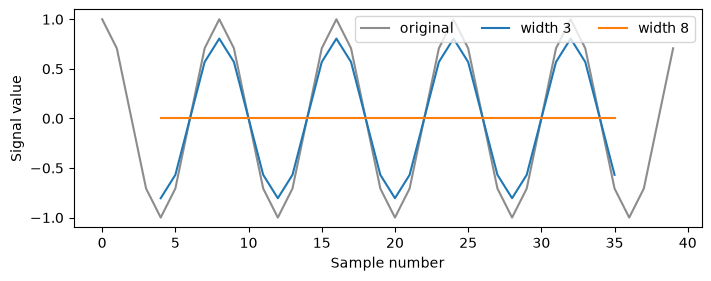

In [21]:
t = np.arange(40)
wave8 = np.cos(2*np.pi*t/8)
fig, ax = plt.subplots(figsize=(7, 2.7), layout="constrained")
ax.plot(t, wave8, color="0.55", label="original")
for w in (3, 8):
    response = abs(np.sin(np.pi*w/8) / (w*np.sin(np.pi/8)))
    print(f"{w} samples: fraction of amplitude retained = {response:.3f}")
    avg = moving_average(wave8, w)
    ax.plot(t[4:-4], avg[4:-4], label=f"width {w}")
ax.set(xlabel="Sample number", ylabel="Signal value")
ax.legend(ncol=3)
plt.show()

The plotted averages use complete windows inside the record. At either edge, zero padding would change the average.

### 5.6. Ringing of a sharp cut-off

Setting every $X_k$ above a cut-off to zero is a convolution with an oscillating kernel. Near a jump, the result overshoots: the **Gibbs phenomenon**. The overshoot stays near 9% of the jump however many frequencies are kept.

In [22]:
for size, K in ((400, 30), (4000, 300)):
    x = (np.arange(size) % (size // 2) < size // 4).astype(float)
    X = np.fft.rfft(x)
    X[K + 1:] = 0
    y = np.fft.irfft(X, n=size)
    print(f'{size} samples, k <= {K}: max {y.max():.3f}, min {y.min():.3f}')
z = np.convolve((np.arange(400) % 200 < 100).astype(float), np.ones(15) / 15, mode="same")
print('moving average: max', z.max().round(3), ' min', z.min().round(3))

400 samples, k <= 30: max 1.090, min -0.090
4000 samples, k <= 300: max 1.090, min -0.090
moving average: max 1.0  min 0.0


## 6. Cross-correlation and phase lag

### 6.1. Aligning two pulses

Two sensors take one reading per second. The first records a pulse of height 1 followed by height 2. The second records the same pulse two seconds later. For a trial lag $\tau$ we pair $x_m$ with $y_{m+\tau}$ and add their products. At zero lag the pulses miss each other. What sum do we expect at lag two?

In [23]:
x = np.array([0, 1, 2, 0, 0, 0])
y = np.array([0, 0, 0, 1, 2, 0])
print("Lag 0:", x @ y)
print("Lag 2:", x[:-2] @ y[2:])

Lag 0: 0
Lag 2: 5


At lag two the sum is $1^2+2^2=5$. For sensors with different baselines and scales we first subtract each mean and divide by its standard deviation. The **cross-correlation** here adds the resulting products at each lag and divides by the record length. Its peak should still occur at two seconds.

In [24]:
def cross_correlation(x, y, axis=-1):
    """Correlation of y against x at every lag, computed by FFT.

    Both series are standardised (mean removed, divided by the standard
    deviation). Then c[tau] is the sum of x[k] * y[k + tau] over the pairs
    inside the record, divided by n. A maximum at tau > 0 means that y
    follows x by tau samples.

    Returns
    -------
    lags : numpy.ndarray of int, shape (2 n - 1,)
        The lags -(n - 1), ..., n - 1.
    c : numpy.ndarray
        The correlation at each lag, along axis.

    Examples
    --------
    >>> lags, c = cross_correlation([1.0, 2.0, 0.0, 0.0], [0.0, 1.0, 2.0, 0.0])
    >>> int(lags[np.argmax(c)])
    1
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    y = np.moveaxis(np.asarray(y, dtype=float), axis, -1)
    n = x.shape[-1]
    xs = (x - x.mean(axis=-1, keepdims=True)) / x.std(axis=-1, keepdims=True)
    ys = (y - y.mean(axis=-1, keepdims=True)) / y.std(axis=-1, keepdims=True)
    N = 2 ** math.ceil(math.log2(2 * n - 1))  # room for all 2n - 1 lags
    c = np.fft.irfft(np.fft.rfft(xs, N).conj() * np.fft.rfft(ys, N), N) / n
    # the circular result holds lags 0 .. n - 1, then the negative lags
    c = np.concatenate([c[..., N - n + 1:], c[..., :n]], axis=-1)
    return np.arange(-(n - 1), n), np.moveaxis(c, -1, axis)

In [25]:
lags, correlation = cross_correlation(x, y)
best = lags[np.argmax(correlation)]
print("Lag of the largest correlation:", best, "samples")
assert best == 2
xs, ys = (x-x.mean())/x.std(), (y-y.mean())/y.std()
np.testing.assert_allclose(correlation, np.correlate(ys, xs, 'full') / x.size, atol=1e-12)

Lag of the largest correlation: 2 samples


### 6.2. Delay within a repeating cycle

Use two cosines with period eight seconds. The second peaks two seconds later, a quarter of a cycle. At their common frequency the **phase lag** should be $360^\circ(2/8)=90^\circ$. With Fourier coefficients $X$ for the first sensor and $Y$ for the second, the angle of $X\overline{Y}$ measures this lag. A phase difference gives a delay modulo one period.

In [26]:
t = np.arange(32)
a = np.cos(2*np.pi*t/8)
b = np.cos(2*np.pi*(t-2)/8)
k = 4                                   # four cycles in 32 seconds
X, Y = np.fft.rfft(a), np.fft.rfft(b)
phase = np.degrees(np.angle(X[k] * Y[k].conj()))
print(f"Phase lag: {phase:.1f} degrees; delay: {8*phase/360:.2f} seconds")
np.testing.assert_allclose(phase, 90)

Phase lag: 90.0 degrees; delay: 2.00 seconds


## Closing exercise — Population cycles

Blasius and colleagues measured two populations in the same vessel. Rotifers are small animals that eat algae. In experiment C9 the nutrient supply repeated every eight days. Can we detect that period in each population? Do the rotifer peaks follow the algae peaks?

1. Inspect the time intervals. Estimate both densities at whole days starting at day 0 and count the daily pairs. The FFT assumes equal time intervals. Linear interpolation gives us a daily grid, but it can miss a peak or trough between measurements.
2. Find the strongest period between 3 and 20 days for each population. First use the original frequency grid. Then use a Hann window and a 4096-point FFT.
3. Find the strongest cross-correlation at a delay from 0 to 7 days. Would an eight-day moving average help us detect the cycle?

The following cell reads C9.csv from the notebook folder or its data subdirectory. If both are empty it retrieves the course copy. The columns used are time (days), algae density (millions of cells per ml) and rotifer density (animals per ml).

[Original study in *Nature*](https://www.nature.com/articles/s41586-019-1857-0) · [Experimental records on figshare](https://doi.org/10.6084/m9.figshare.10045976)

In [27]:
from pathlib import Path
from urllib.request import urlopen


def read_run(number):
    filename = f"C{number}.csv"
    path = Path("data") / filename
    if not path.exists():
        local = Path(filename)
        if local.exists():
            path = local
        else:
            url = f"https://raw.githubusercontent.com/borisbolliet/attractor/lecture-22/data/{filename}"
            with urlopen(url, timeout=30) as response:
                contents = response.read()
            path.parent.mkdir(exist_ok=True)
            path.write_bytes(contents)
    rows = np.genfromtxt(path, delimiter=",", skip_header=1, usecols=(0, 1, 2))
    return rows[np.isfinite(rows).all(axis=1)]


rows = read_run(9)
print("First three paired observations (time, algae, rotifers):")
print(rows[:3])

First three paired observations (time, algae, rotifers):
[[ 0.    1.92 16.25]
 [ 1.02  1.58 43.75]
 [ 2.05  0.62 42.94]]


### Worked solution 1. Sampling

We inspect the original times before interpolating. The longest gap is 1.31 days. How does that compare with the eight-day nutrient cycle? The dots below show the measurements at their original times. The line joins the daily estimates.

Minimum, median and maximum interval (days): [0.64 1.01 1.31]
141 paired values on the daily grid, days 0 to 140.


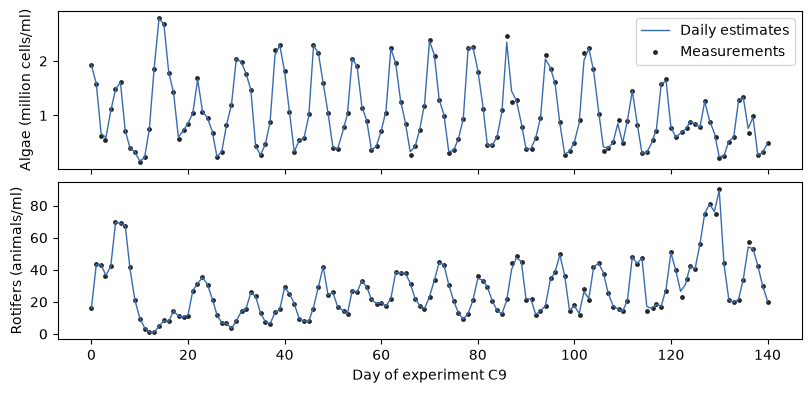

In [28]:
def uniform(t, x, dt=1.0):
    """Interpolate samples linearly onto equally spaced times.

    Parameters
    ----------
    t : numpy.ndarray, shape (n,)
        Sample times, strictly increasing.
    x : numpy.ndarray, shape (n,)
        Sample values at the times t.
    dt : float, optional
        Spacing of the new times, in the units of t (default 1.0).

    Returns
    -------
    tu : numpy.ndarray
        The times t[0], t[0] + dt, t[0] + 2 dt, ..., up to t[-1].
    xu : numpy.ndarray
        x interpolated linearly at the times tu.

    Raises
    ------
    ValueError
        If t does not increase strictly; np.interp would then return
        meaningless values without raising an error.

    Examples
    --------
    >>> tu, xu = uniform([0.0, 0.9, 2.2, 3.1], [0.0, 1.8, 4.4, 6.2])
    >>> tu, xu
    (array([0., 1., 2., 3.]), array([0., 2., 4., 6.]))
    """
    t = np.asarray(t, dtype=float)
    if np.any(np.diff(t) <= 0):
        raise ValueError("sample times must increase strictly")
    m = int((t[-1] - t[0]) // dt) + 1
    tu = t[0] + dt * np.arange(m)
    return tu, np.interp(tu, t, x)


def daily_counts(rows):
    measured_time, algae, rotifers = rows.T
    days, daily_algae = uniform(measured_time, algae)
    _, daily_rotifers = uniform(measured_time, rotifers)
    return days, np.column_stack([daily_algae, daily_rotifers])


intervals = np.diff(rows[:, 0])
days, counts = daily_counts(rows)
print("Minimum, median and maximum interval (days):",
      np.round([intervals.min(), np.median(intervals), intervals.max()], 2))
print(f"{len(days)} paired values on the daily grid, days {days[0]:g} to {days[-1]:g}.")
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 3.8), layout="constrained")
for ax, values, measured, label in zip(axes, counts.T, rows[:, 1:].T, ["Algae (million cells/ml)", "Rotifers (animals/ml)"]):
    ax.plot(days, values, lw=1, color="#386cb0", label="Daily estimates")
    ax.scatter(rows[:, 0], measured, s=6, color="#252525", label="Measurements")
    ax.set_ylabel(label)
axes[0].legend()
axes[-1].set_xlabel("Day of experiment C9")
plt.show()

### Worked solution 2. Periods

The time axis runs down the rows of the array. We take the transform along that axis to obtain a separate spectrum for each column. Search only frequencies from $1/20$ to $1/3$ cycles per day.

FFT length  141, Hann False: algae 7.83 d, rotifers 8.29 d
FFT length 4096, Hann True : algae 8.02 d, rotifers 8.06 d


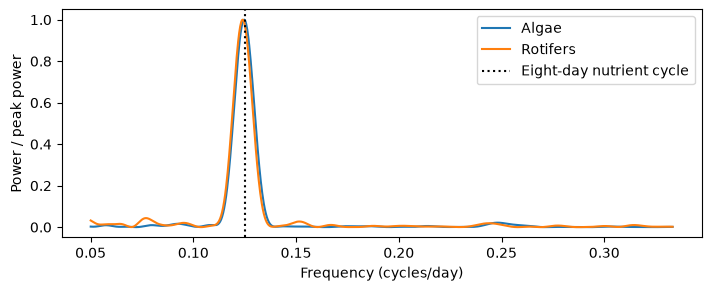

In [29]:
for fft_size, taper in [(len(days), False), (4096, True)]:
    f, power = periodogram(counts, n=fft_size, window=taper, axis=0)
    periods = dominant_period(f, power, shortest=3, longest=20, axis=0)
    print(f"FFT length {fft_size:4}, Hann {str(taper):5}: algae {periods[0]:.2f} d, rotifers {periods[1]:.2f} d")

band = (f >= 1/20) & (f <= 1/3)
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
for channel, label in enumerate(["Algae", "Rotifers"]):
    relative_power = power[band, channel] / power[band, channel].max()
    ax.plot(f[band], relative_power, label=label)
ax.axvline(1/8, ls=":", color="black", label="Eight-day nutrient cycle")
ax.set(xlabel="Frequency (cycles/day)", ylabel="Power / peak power")
ax.legend()
plt.show()

On the original grid the strongest algae bin is $k=18$, which gives $141/18=7.83$ days. The neighbouring bin gives $141/17=8.29$ days. After tapering and padding, the maxima are at 8.02 days for algae and 8.06 days for rotifers. Both are close to the eight-day nutrient cycle.

### Worked solution 3. Delay

We take algae as the first series and rotifers as the second. A positive lag compares today's algae with a later rotifer measurement. Restrict the search to one cycle to avoid picking a peak a whole cycle later.

In [30]:
lags, c = cross_correlation(counts[:, 0], counts[:, 1])
one_cycle = (lags >= 0) & (lags <= 7)
for lag, value in zip(lags[one_cycle], c[one_cycle]):
    print(f"{lag} d: {value:+.3f}")
best = lags[one_cycle][np.argmax(c[one_cycle])]
print(f"The rotifers follow the algae by about {best} days.")

0 d: -0.047
1 d: +0.271
2 d: +0.325
3 d: +0.124
4 d: -0.164
5 d: -0.348
6 d: -0.373
7 d: -0.199
The rotifers follow the algae by about 2 days.


The best whole-day shift is two days. An eight-day moving average would largely remove the oscillation whose timing we wanted to compare.

### Optional exercise — Compare runs

Does a different experiment give the same period and delay? Change the list in the next cell to include run 2, or use all ten runs. Each missing file downloads when its run is requested. For each run, find the strongest shared frequency and convert the phase difference there into days. Compare this estimate with the whole-day lag.

In [31]:
run_numbers = [9]                        # try [2, 9] or range(1, 11)
print("Run    Algae period (d)   Joint period (d)   Lag (d)   Phase delay (d)")
for run in run_numbers:
    _, pair = daily_counts(read_run(run))
    f, coeff = fourier(pair, n=4096, axis=0)
    alg_period = dominant_period(f, np.abs(coeff[:, 0])**2, 3, 20)
    cross_spectrum = coeff[:, 0] * coeff[:, 1].conj()
    band = (f >= 1/20) & (f <= 1/3)
    k = np.flatnonzero(band)[np.argmax(np.abs(cross_spectrum[band]))]
    period = 1/f[k]
    phase_delay = period * np.angle(cross_spectrum[k]) / (2*np.pi)
    lags, c = cross_correlation(pair[:, 0], pair[:, 1])
    within_period = (lags >= 0) & (lags < period)
    lag = lags[within_period][np.argmax(c[within_period])]
    print(f"C{run:<3} {alg_period:12.2f} {period:17.2f} {lag:9} {phase_delay:17.2f}")

Run    Algae period (d)   Joint period (d)   Lag (d)   Phase delay (d)
C9           8.02              8.05         2              1.64


For C9 the phase at the shared peak gives about 1.64 days. The cross-correlation used the whole signal and tested integer lags. The phase estimate uses one frequency and can give a fraction of a day. When you include C2, its algae peak is near 7.11 days.